# Linear Regression: Predicting Vehicle Fuel Economy

**Family:** Supervised learning | **Level:** Beginner | **Dataset:** `auto_mpg` | **Runs on:** CPU, about 1 minute(s)

Fit and diagnose ordinary least squares on real car data, from the normal equations to residual checks.

## Table of Contents

1. [Learning Objectives](#1.-Learning-Objectives)
2. [Real-World Problem](#2.-Real-World-Problem)
3. [Research Paper](#3.-Research-Paper)
4. [Mathematical Foundation](#4.-Mathematical-Foundation)
5. [Dataset Introduction](#5.-Dataset-Introduction)
6. [Exploratory Data Analysis](#6.-Exploratory-Data-Analysis)
7. [Data Preprocessing](#7.-Data-Preprocessing)
8. [Algorithm Implementation](#8.-Algorithm-Implementation)
9. [Model Training](#9.-Model-Training)
10. [Evaluation](#10.-Evaluation)
11. [Visualization](#11.-Visualization)
12. [Interpretation](#12.-Interpretation)
13. [Experiments and Challenges](#13.-Experiments-and-Challenges)
14. [Research Discussion](#14.-Research-Discussion)
15. [Summary and Further Reading](#15.-Summary-and-Further-Reading)

## 1. Learning Objectives

**After this notebook you will understand:**

- How least squares chooses coefficients and why the normal equations work
- Why we split the data before scaling and fitting
- How to read RMSE, MAE and R-squared and compare them with a dummy baseline
- How collinearity and nonlinearity show up in the diagnostics

**Prerequisites:**

- Python and pandas basics
- Matrices and the dot product
- Mean and variance

**Skills you will have afterwards:**

- Build a leakage free regression pipeline
- Write OLS from scratch with NumPy
- Diagnose residuals

## 2. Real-World Problem

**Context.** Fuel economy decides running cost and emissions of a vehicle. Engineers and regulators compare designs by miles per gallon (mpg).

**The problem.** Predict the mpg of a car from engine and body attributes: cylinders, displacement, horsepower, weight, acceleration, model year and origin.

**Why it matters.** A model that links design choices to fuel use supports early design trade studies and fleet level emission estimates.

**Why machine learning.** Many attributes interact and the relation is estimated from past cars, not derived from physics. A statistical fit is the quickest honest first model.

**Why this algorithm.** Linear regression is the simplest model with interpretable coefficients. It sets the baseline that more flexible models must beat.

## 3. Research Paper

Entries are grouped by type. Bibliographic details marked *verified* were checked against the publisher record (Crossref) or the arXiv abstract page on 2026-11-17. Entries marked *not verified* come from the author's knowledge and must be checked before citing.

### The Elements of Statistical Learning (2nd ed.)

- **Type:** foundational paper
- **Authors:** Hastie, T., Tibshirani, R. and Friedman, J.
- **Year and venue:** 2009, Springer
- **DOI or URL:** https://doi.org/10.1007/978-0-387-84858-7
- **Verification:** not verified in build environment
- **Research objective:** Textbook on statistical learning.
- **Methodology:** Textbook.
- **Dataset:** Not applicable.
- **Main findings:** Reference text.
- **Limitations:** Textbook.

### Ridge Regression: Biased Estimation for Nonorthogonal Problems

- **Type:** foundational paper
- **Authors:** Hoerl, A. E. and Kennard, R. W.
- **Year and venue:** 1970, Technometrics 12(1):55-67
- **DOI or URL:** https://doi.org/10.1080/00401706.1970.10488634
- **Verification:** Crossref 2026-11-17
- **Research objective:** Stabilise least squares when predictors are nearly collinear.
- **Methodology:** Add a multiple of the identity to X'X before inversion.
- **Dataset:** Illustrative examples.
- **Main findings:** A small bias can cut the variance and the mean squared error of coefficients.
- **Limitations:** Keeps every predictor, so it does not select variables.

**Relationship to this notebook.** The Auto MPG data was donated to the UCI repository in 1993 and is a standard regression teaching set. Hastie et al. give the least squares theory used here. Hoerl and Kennard motivate why collinear predictors, which this dataset has, make coefficients unstable. This notebook does not reproduce the experimental protocol of any listed paper. It uses a different dataset and split, so numbers are not comparable with the paper.

## 4. Mathematical Foundation

**Model.** For a row $x_i \in \mathbb{R}^p$ and target $y_i$:

$$y_i = \beta_0 + x_i^\top \beta + \varepsilon_i, \qquad \varepsilon_i \sim (0, \sigma^2)$$

**Objective (residual sum of squares).**

$$\hat\beta = \arg\min_{\beta} \; \sum_{i=1}^{n} \left(y_i - \beta_0 - x_i^\top \beta\right)^2 = \arg\min_{\beta}\; \lVert y - A\beta \rVert_2^2$$

where $A$ is the design matrix with a leading column of ones.

**Optimisation.** Setting the gradient to zero gives the normal equations

$$A^\top A\, \hat\beta = A^\top y \quad\Rightarrow\quad \hat\beta = (A^\top A)^{-1} A^\top y.$$

Gradient descent is the alternative: $\beta \leftarrow \beta - \eta \cdot \tfrac{2}{n} A^\top (A\beta - y)$.

**Notation.** $n$ rows, $p$ features, $\beta_0$ intercept, $\eta$ learning rate, $\varepsilon$ noise.

**Assumptions.** Linear relation in the parameters, errors with mean zero and constant variance, errors uncorrelated with the features, and (for standard errors) no perfect collinearity.

**Limitations.** Sensitive to outliers because errors are squared. Cannot capture curvature or interactions unless you add terms. Unstable coefficients when features are strongly correlated.

## 5. Dataset Introduction

**Auto MPG** (Quinlan, 1993) from the UCI Machine Learning Repository, licence CC BY 4.0, DOI 10.24432/C5859H. The UCI page lists 398 cars; this repository uses the 392 rows without missing horsepower as shipped in `mlxtend`. Target `mpg` (continuous). Features: `cylinders`, `displacement` (cubic inches), `horsepower`, `weight` (pounds), `acceleration` (seconds from 0 to 60 mph), `model_year` (1970 to 1982), `origin` (1 US, 2 Europe, 3 Japan, coded as numbers). All features are numeric. Known limits: cars from 1970 to 1982 only, so the model says nothing about modern vehicles.

The table printed below the next cell comes from the dataset registry in `src/ml_lab/data/registry.py`. Licence terms belong to the data provider, not to this repository.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.base import clone
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.inspection import permutation_importance
from sklearn.model_selection import cross_validate
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from ml_lab.data import load_dataset, missing_report
from ml_lab.preprocessing import split_three_way, build_preprocessor, make_model_pipeline, feature_names
from ml_lab.evaluation import evaluate_estimator, compare_models
from ml_lab.experiments import ExperimentRecord, save_figure
from ml_lab.utils import set_seed, print_environment
from ml_lab import visualization as viz

NOTEBOOK_ID = "linear_regression"
SEED = 42
set_seed(SEED)
viz.apply_style()
print_environment()

python 3.13.18 | Linux-6.18.44-fc-v595-x86_64-with-glibc2.39
  numpy==2.5.3
  pandas==3.0.5
  scipy==1.18.1
  scikit-learn==1.9.1
  matplotlib==3.11.2
  xgboost==3.4.1
  lightgbm==4.7.0
  catboost==1.2.10
  umap-learn==0.6.0
  torch==2.15.0
  gymnasium==1.4.0


In [2]:
bundle = load_dataset("auto_mpg")
data = bundle.frame
TASK = bundle.task
TARGET = bundle.target
print("task:", TASK, "| target:", TARGET, "| shape:", data.shape)
display(pd.Series(bundle.describe_source(), name="source").to_frame())
display(data.head())

task: regression | target: mpg | shape: (392, 8)


,source
title,Auto MPG
source,UCI Machine Learning Repository
url,https://archive.ics.uci.edu/dataset/9/auto+mpg
license,CC BY 4.0
doi,10.24432/C5859H
rows,392
features,7
limits,Cars from 1970 to 1982 only. Six rows without ...


,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,mpg
0,8.0,307.0,130.0,3504.0,12.0,70.0,1.0,18.0
1,8.0,350.0,165.0,3693.0,11.5,70.0,1.0,15.0
2,8.0,318.0,150.0,3436.0,11.0,70.0,1.0,18.0
3,8.0,304.0,150.0,3433.0,12.0,70.0,1.0,16.0
4,8.0,302.0,140.0,3449.0,10.5,70.0,1.0,17.0


## 6. Exploratory Data Analysis

We look at size, types, missing values, the target, feature distributions, correlation and outliers before any modelling. Look for strong correlation between `displacement`, `cylinders`, `horsepower` and `weight`, and for a curved relation between weight and mpg.

In [3]:
print("Rows and columns:", data.shape)
display(data.dtypes.value_counts().rename("columns by dtype").to_frame())
display(data.describe().T.round(3).head(20))
missing = missing_report(data)
print("Columns with missing values:", len(missing))
display(missing)
print("Duplicate rows:", int(data.duplicated().sum()))

Rows and columns: (392, 8)


,columns by dtype
float64,8


,count,mean,std,min,25%,50%,75%,max
cylinders,392.0,5.472,1.706,3.0,4.000,4.00,8.000,8.0
displacement,392.0,194.412,104.644,68.0,105.000,151.00,275.750,455.0
horsepower,392.0,104.469,38.491,46.0,75.000,93.50,126.000,230.0
weight,392.0,2977.584,849.403,1613.0,2225.250,2803.50,3614.750,5140.0
acceleration,392.0,15.541,2.759,8.0,13.775,15.50,17.025,24.8
model_year,392.0,75.980,3.684,70.0,73.000,76.00,79.000,82.0
origin,392.0,1.577,0.806,1.0,1.000,1.00,2.000,3.0
mpg,392.0,23.446,7.805,9.0,17.000,22.75,29.000,46.6


Columns with missing values: 0


,missing,percent


Duplicate rows: 0


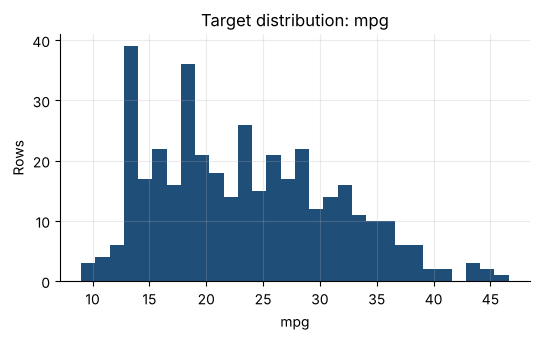

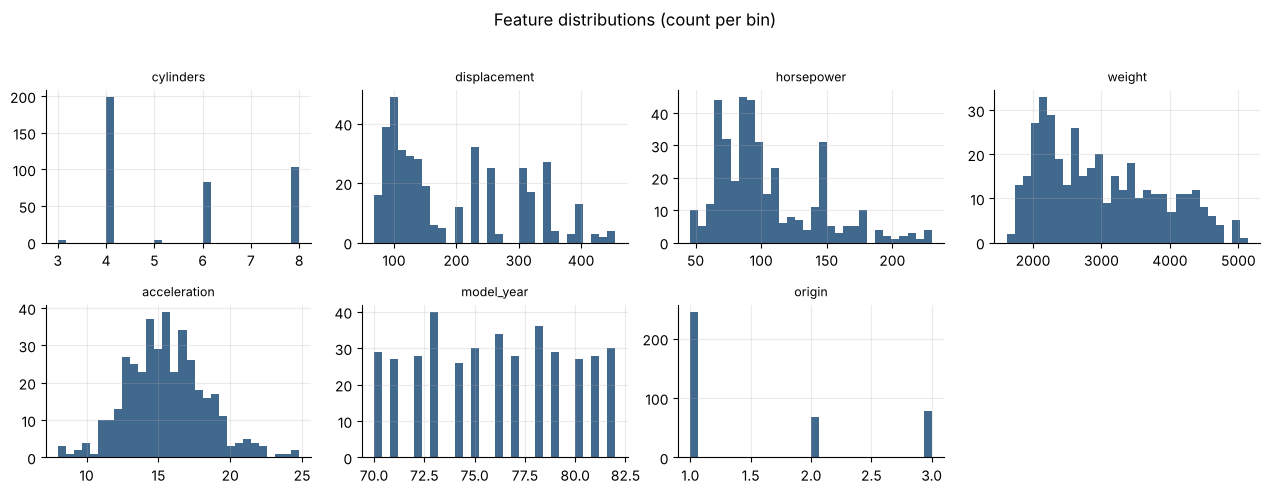

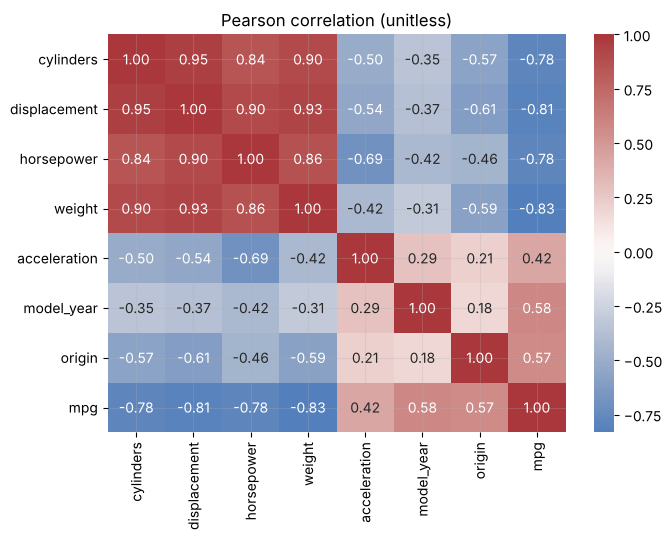

,feature,outliers,percent
0,acceleration,11,2.81
1,horsepower,10,2.55
2,cylinders,0,0.00
3,displacement,0,0.00
4,weight,0,0.00
5,model_year,0,0.00
6,origin,0,0.00


In [4]:
fig = viz.plot_target(data[TARGET], TASK)
plt.show()
fig = viz.plot_distributions(data.drop(columns=[TARGET]))
plt.show()
fig = viz.plot_correlation(data)
plt.show()
display(viz.outlier_table(data.drop(columns=[TARGET])).head(8))

## 7. Data Preprocessing

Rules used here:

- Split first, then fit imputers, scalers and encoders on the training rows only. This prevents data leakage.
- The test set is touched once, at the end.
- Order inside the pipeline: impute, scale or encode, then model.


In [5]:

X, y = data.drop(columns=[TARGET]), data[TARGET]
X_train, X_val, X_test, y_train, y_val, y_test = split_three_way(X, y, task=TASK, seed=SEED)
print("train / validation / test rows:", len(X_train), len(X_val), len(X_test))
if TASK == "classification":
    split_rates = pd.DataFrame({"train": y_train.value_counts(normalize=True),
                                "validation": y_val.value_counts(normalize=True),
                                "test": y_test.value_counts(normalize=True)}).round(3)
    display(split_rates)
prep = build_preprocessor(X_train, scale=True, encode="onehot")
Xtr = prep.fit_transform(X_train)   # fit on train only
Xva, Xte = prep.transform(X_val), prep.transform(X_test)
print("transformed train shape:", Xtr.shape)

train / validation / test rows: 234 79 79
transformed train shape: (234, 7)


## 8. Algorithm Implementation

### 8.1 Concept

Least squares draws the hyperplane that minimises the sum of squared vertical distances to the data. With standardised features each coefficient is the change in mpg for a one standard deviation change in that feature, holding the others fixed.

### 8.2 Python implementation from scratch

We implement the normal equations and gradient descent with NumPy and check that both match scikit-learn. Implementing it yourself teaches what `fit` does. For production use the library version.

max coefficient gap, normal vs sklearn: 7.76601005725297e-14
max coefficient gap, gradient descent vs sklearn: 0.03375325620287484
validation RMSE scratch: 2.8429 | sklearn: 2.8429


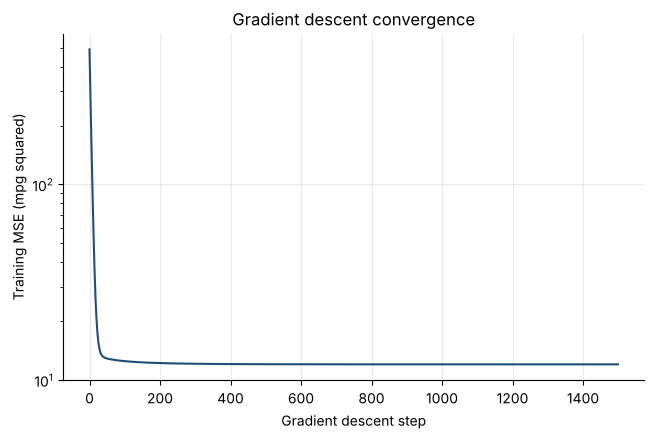

In [6]:
ytr, yva = y_train.values, y_val.values

class LinearRegressionScratch:
    def fit_normal(self, X, y):
        A = np.c_[np.ones(len(X)), X]
        self.w = np.linalg.solve(A.T @ A, A.T @ y)   # normal equations
        return self

    def fit_gd(self, X, y, lr=0.05, steps=1500):
        A = np.c_[np.ones(len(X)), X]
        w = np.zeros(A.shape[1])
        self.history = []
        for _ in range(steps):
            w -= lr * (2 / len(A)) * A.T @ (A @ w - y)
            self.history.append(np.mean((A @ w - y) ** 2))
        self.w = w
        return self

    def predict(self, X):
        return np.c_[np.ones(len(X)), X] @ self.w

normal = LinearRegressionScratch().fit_normal(Xtr, ytr)
descent = LinearRegressionScratch().fit_gd(Xtr, ytr)
reference = LinearRegression().fit(Xtr, ytr)
print("max coefficient gap, normal vs sklearn:", np.abs(normal.w[1:] - reference.coef_).max())
print("max coefficient gap, gradient descent vs sklearn:", np.abs(descent.w[1:] - reference.coef_).max())
print("validation RMSE scratch:", round(float(np.sqrt(np.mean((normal.predict(Xva) - yva) ** 2))), 4),
      "| sklearn:", round(float(np.sqrt(np.mean((reference.predict(Xva) - yva) ** 2))), 4))
plt.plot(descent.history)
plt.yscale("log")
plt.xlabel("Gradient descent step")
plt.ylabel("Training MSE (mpg squared)")
plt.title("Gradient descent convergence")
plt.show()

### 8.3 Library implementation

`LinearRegression` solves least squares with an SVD based solver. We wrap it in a pipeline so that imputation and scaling are fitted on training rows only.

### 8.4 Important parameters

| Parameter | Meaning |
|---|---|
| `fit_intercept` | Learn $\beta_0$. Set to `False` only when the target is already centred. |
| `positive` | Force non negative coefficients. |

Ordinary least squares has no regularisation strength to tune. The validation sweep below compares with and without an intercept to show why the intercept matters.

## 9. Model Training

Procedure: fit on the training rows, choose one hyperparameter on the validation rows, refit on training plus validation, then evaluate once on the test rows. The random seed is fixed (`SEED = 42`). 

In [7]:
SELECT = "RMSE"
LOWER_IS_BETTER = True
SCORING = "neg_root_mean_squared_error"
SWEEP_PARAM = "model__fit_intercept"
SWEEP_VALUES = [True, False]

def build_pipeline():
    return make_model_pipeline(X_train, LinearRegression(), scale=True, encode="onehot")

pipe = build_pipeline()
print(pipe.named_steps["model"])
rows = []
for value in SWEEP_VALUES:
    candidate = clone(pipe).set_params(**{SWEEP_PARAM: value}).fit(X_train, y_train)
    rows.append({SWEEP_PARAM: value, **evaluate_estimator(candidate, X_val, y_val, TASK)})
sweep = pd.DataFrame(rows).set_index(SWEEP_PARAM)
display(sweep[[c for c in [SELECT, "R2", "MAE", "Accuracy", "F1", "ROC_AUC", "PR_AUC"] if c in sweep.columns]].round(4))
best_value = sweep[SELECT].idxmin() if LOWER_IS_BETTER else sweep[SELECT].idxmax()
print("best", SWEEP_PARAM, "on validation:", best_value)
final_model = clone(pipe).set_params(**{SWEEP_PARAM: best_value})
X_trainval, y_trainval = pd.concat([X_train, X_val]), pd.concat([y_train, y_val])
final_model.fit(X_trainval, y_trainval)   # refit before test
print("refit on train plus validation rows")

LinearRegression()


,RMSE,R2,MAE
model__fit_intercept,,,
True,2.8429,0.8329,2.1966
False,23.8311,-10.7419,23.6613


best model__fit_intercept on validation: True
refit on train plus validation rows


## 10. Evaluation

Regression metrics: MAE (average absolute error in mpg), RMSE (square root of mean squared error, same unit as mpg, penalises large errors), R-squared (share of variance explained) and MAPE (percentage error, valid because mpg is never zero).

A dummy model gives the floor every real model must beat.

In [8]:
baseline = DummyRegressor(strategy="mean") if TASK == "regression" else DummyClassifier(strategy="prior")
baseline = make_model_pipeline(X_train, baseline, scale=False).fit(X_trainval, y_trainval)
test_metrics = evaluate_estimator(final_model, X_test, y_test, TASK)
baseline_metrics = evaluate_estimator(baseline, X_test, y_test, TASK)
print("Test set, scored once after model choice")
display(compare_models({"baseline": baseline_metrics, "LinearRegression": test_metrics}))
cv = cross_validate(final_model, X_trainval, y_trainval, cv=5, scoring=SCORING, n_jobs=1)
cv_scores = cv["test_score"]
print(f"5-fold CV {SCORING}: mean {cv_scores.mean():.4f}, std {cv_scores.std(ddof=1):.4f}")
record = ExperimentRecord(notebook=NOTEBOOK_ID, family="supervised", algorithm="LinearRegression", dataset="auto_mpg",
                          task=TASK, seed=SEED, config={"param": SWEEP_PARAM, "value": str(best_value)},
                          metrics={k: float(v) for k, v in test_metrics.items()},
                          extra={"baseline": {k: float(v) for k, v in baseline_metrics.items()},
                                 "cv_mean": float(cv_scores.mean()), "cv_std": float(cv_scores.std(ddof=1)),
                                 "cv_scoring": SCORING, "select_metric": SELECT})
print("saved", record.save().name)

Test set, scored once after model choice


,MAE,MSE,RMSE,R2,MAPE_percent
baseline,5.8810,51.6203,7.1847,-0.0114,30.1965
LinearRegression,2.4198,10.7109,3.2727,0.7902,11.7892


5-fold CV neg_root_mean_squared_error: mean -3.3658, std 0.4028
saved linear_regression.json


## 11. Visualization

All plots use the test rows unless the title says otherwise.

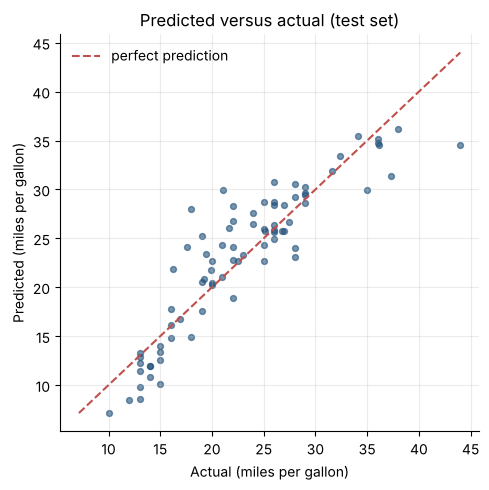

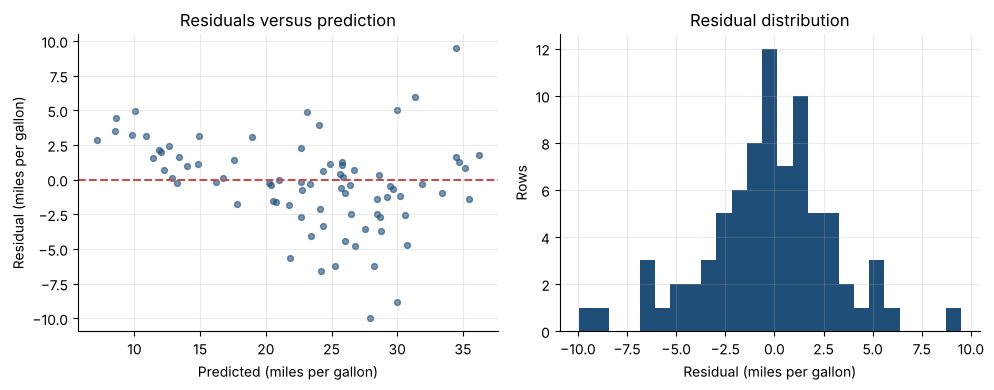

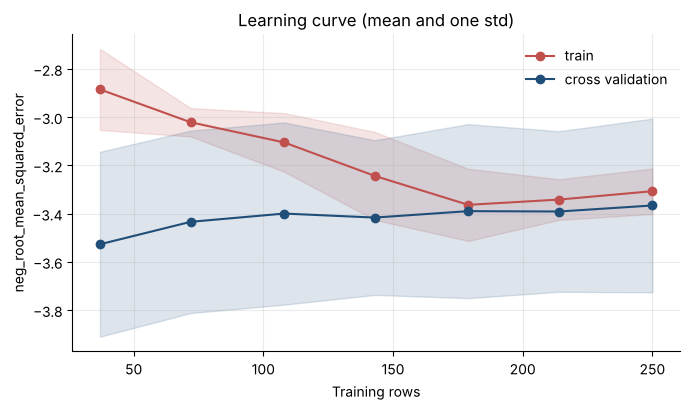

In [9]:
pred = final_model.predict(X_test)
fig = viz.plot_pred_vs_actual(y_test, pred, unit="(miles per gallon)")
save_figure(fig, NOTEBOOK_ID, "pred_vs_actual"); plt.show()
fig = viz.plot_residuals(y_test, pred, unit="(miles per gallon)")
save_figure(fig, NOTEBOOK_ID, "residuals"); plt.show()
fig = viz.plot_learning_curve(final_model, X_trainval, y_trainval, scoring=SCORING)
save_figure(fig, NOTEBOOK_ID, "learning_curve"); plt.show()

## 12. Interpretation

Read the permutation importance chart as: how much does the error grow if one feature is shuffled? Because several features are correlated (weight, displacement, cylinders), importance is shared between them and individual coefficients can be misleading. Check the residual plot for curvature, which would mean a straight line is too simple.

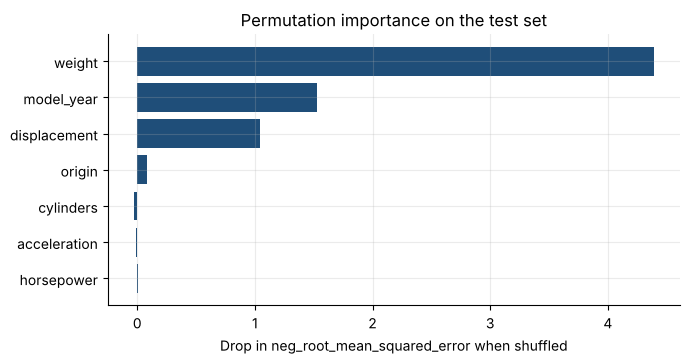

Top features: weight, model_year, displacement, origin, horsepower
Largest test errors:


,actual,predicted,abs_error
110,18.0,27.957,9.957
388,44.0,34.509,9.491
268,21.1,29.958,8.858
361,17.6,24.165,6.565
208,19.0,25.264,6.264



Test RMSE: 3.2727 | baseline RMSE: 7.1847
Cross validation spread (std): 0.4028. A test gap larger than this spread is meaningful.


In [10]:
perm = permutation_importance(final_model, X_test, y_test, scoring=SCORING, n_repeats=10, random_state=SEED)
importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values(ascending=False)
fig = viz.plot_importance(importance.index, importance.values, title="Permutation importance on the test set",
                          top=12, xlabel="Drop in " + SCORING + " when shuffled")
save_figure(fig, NOTEBOOK_ID, "importance"); plt.show()
print("Top features:", ", ".join(importance.index[:5]))
errors = (y_test.values - final_model.predict(X_test)) if TASK == "regression" else (y_test.values != final_model.predict(X_test))
if TASK == "regression":
    worst = pd.DataFrame({"actual": y_test.values, "predicted": final_model.predict(X_test)}, index=y_test.index)
    worst["abs_error"] = (worst["actual"] - worst["predicted"]).abs()
    print("Largest test errors:")
    display(worst.sort_values("abs_error", ascending=False).head(5).round(3))
else:
    print("Misclassified test rows:", int(errors.sum()), "of", len(errors))
print()
print(f"Test {SELECT}: {test_metrics[SELECT]:.4f} | baseline {SELECT}: {baseline_metrics[SELECT]:.4f}")
print(f"Cross validation spread (std): {cv_scores.std(ddof=1):.4f}. A test gap larger than this spread is meaningful.")

## 13. Experiments and Challenges

### Experiment 1: Collinearity: variance inflation factors

Variance inflation factor (VIF) of feature $j$ is $1/(1-R_j^2)$, where $R_j^2$ comes from regressing feature $j$ on the others. Large values mean the coefficient is poorly determined. We then drop the worst feature and compare cross validated RMSE on the training plus validation rows.

In [11]:
from sklearn.model_selection import cross_val_score
def cv_rmse(model, X_data=None, y_data=None):
    scores = cross_val_score(model, X_data if X_data is not None else X_trainval,
                             y_data if y_data is not None else y_trainval,
                             cv=5, scoring="neg_root_mean_squared_error")
    return -scores.mean(), scores.std(ddof=1)
Z = StandardScaler().fit_transform(X_trainval)
vif = {}
for j, name in enumerate(X_trainval.columns):
    others = np.delete(Z, j, axis=1)
    r2 = LinearRegression().fit(others, Z[:, j]).score(others, Z[:, j])
    vif[name] = 1 / (1 - r2)
vif = pd.Series(vif).sort_values(ascending=False)
display(vif.round(2).to_frame("VIF"))
worst = vif.index[0]
full = cv_rmse(make_model_pipeline(X_trainval, LinearRegression()))
reduced = cv_rmse(make_model_pipeline(X_trainval.drop(columns=[worst]), LinearRegression()), X_trainval.drop(columns=[worst]))
print(f"CV RMSE all features: {full[0]:.3f} +- {full[1]:.3f}")
print(f"CV RMSE without {worst}: {reduced[0]:.3f} +- {reduced[1]:.3f}")

,VIF
displacement,21.49
cylinders,11.12
weight,10.16
horsepower,9.93
acceleration,2.68
origin,1.75
model_year,1.28


CV RMSE all features: 3.366 +- 0.403
CV RMSE without displacement: 3.375 +- 0.414


### Experiment 2: Transform the target

Fuel economy is bounded below and right skewed. Modelling $\log(\text{mpg})$ turns multiplicative effects into additive ones. We compare cross validated RMSE measured back on the mpg scale.

In [12]:
from sklearn.model_selection import cross_val_score
def cv_rmse(model, X_data=None, y_data=None):
    scores = cross_val_score(model, X_data if X_data is not None else X_trainval,
                             y_data if y_data is not None else y_trainval,
                             cv=5, scoring="neg_root_mean_squared_error")
    return -scores.mean(), scores.std(ddof=1)
from sklearn.compose import TransformedTargetRegressor
plain = cv_rmse(make_model_pipeline(X_trainval, LinearRegression()))
logged = cv_rmse(TransformedTargetRegressor(make_model_pipeline(X_trainval, LinearRegression()), func=np.log, inverse_func=np.exp))
print(f"CV RMSE raw target: {plain[0]:.3f} +- {plain[1]:.3f}")
print(f"CV RMSE log target: {logged[0]:.3f} +- {logged[1]:.3f}")

CV RMSE raw target: 3.366 +- 0.403
CV RMSE log target: 3.040 +- 0.348


### Experiment 3: Add curvature with squared terms

If the residual plot bends, add squared terms. This moves towards polynomial regression (see that notebook).

In [13]:
from sklearn.model_selection import cross_val_score
def cv_rmse(model, X_data=None, y_data=None):
    scores = cross_val_score(model, X_data if X_data is not None else X_trainval,
                             y_data if y_data is not None else y_trainval,
                             cv=5, scoring="neg_root_mean_squared_error")
    return -scores.mean(), scores.std(ddof=1)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
linear = cv_rmse(make_model_pipeline(X_trainval, LinearRegression()))
curved = cv_rmse(make_pipeline(build_preprocessor(X_trainval), PolynomialFeatures(2, include_bias=False), StandardScaler(), LinearRegression()))
print(f"CV RMSE linear: {linear[0]:.3f} +- {linear[1]:.3f}")
print(f"CV RMSE degree 2 terms: {curved[0]:.3f} +- {curved[1]:.3f}")

CV RMSE linear: 3.366 +- 0.403
CV RMSE degree 2 terms: 2.925 +- 0.195


### Exercises for learners

1. Fit the model on `model_year >= 76` rows only and test on earlier years. What does this tell you about extrapolation?
2. Add Huber loss (`HuberRegressor`) and compare the largest residuals.
3. Compute 95 percent bootstrap intervals for the coefficients with `ml_lab.metrics.bootstrap_interval`.

## 14. Research Discussion

Hastie et al. present least squares as the base case for linear methods. Our notebook shows the same normal equations numerically. The collinearity experiment connects to the motivation of Hoerl and Kennard for ridge regression.

**Dataset and method differences.** The papers above use other datasets, other splits and often other implementations. We do not claim that our numbers agree or disagree with them. What this notebook can show is whether the behaviour described in the paper (for example the effect of a parameter) appears on our data.

**Possible improvements.** Use regularised variants (ridge, lasso), model the log target, add interaction terms, or move to tree ensembles if curvature dominates.

**Research limitations.** One dataset, one split seed for the headline number, and small test sets for the UCI data. Cross validation spread is reported to show how unstable a single split can be.

## 15. Summary and Further Reading

**Key takeaways**

- Least squares has a closed form, and gradient descent approaches the same solution (the small gap is printed in the scratch cell).
- Always compare with a dummy baseline.
- Correlated features make single coefficients unreliable even when predictions are fine.

**Use cases.** Quick baselines, interpretable cost or demand models, and benchmarks for more complex models.

**Limitations.** Linear in the parameters, sensitive to outliers, and unstable under collinearity.

**Recommended next notebook.** Ridge Regression, which stabilises coefficients under collinearity.

**Further reading.** See `references.md` in this folder and the library documentation for the classes used above.